# 🖐️ Transfer Learning with VGG16: Easy Step-by-Step Version
### Hand-gesture images → a `df` table → VGG16 Feature Extraction vs. VGG16 Fine-Tuning

**Author:** `<your-name>` · **GitHub:** `<your-github-username>`

This is the **easy version** of the assignment. The dataset is turned into **one table called `df`**, and every step after that uses `df`, just like a normal pandas project.

| Step | What happens |
|---|---|
| 1 | Load the libraries |
| 2 | Upload the ZIP and extract it |
| 3 | **Create `df`**: one row per image |
| 4 | Explore `df`: counts, sizes, broken files, duplicates |
| 5 | Look at the images |
| 6 | Split `df` into train / validation / test |
| 7 | Load the images into arrays |
| 8 | Build Model 1: VGG16 **feature extraction** |
| 9 | Train Model 1 |
| 10 | Model 2: VGG16 **fine-tuning** |
| 11 | Test both models |
| 12 | Find the wrong predictions |
| 13 | Compare the models |
| 14 | Save the model and predict one image |
| 15 | Download the results |

### ▶️ How to run in Google Colab
1. `Runtime → Change runtime type → T4 GPU → Save`
2. `Runtime → Run all`
3. When the upload button appears in Step 2, choose **`test.zip`**.
4. If anything goes wrong: `Runtime → Restart session`, then `Runtime → Run all`.

### 📖 Key words (in one line each)
- **CNN:** a neural network that looks at images in small patches to find edges, then shapes, then objects.
- **Transfer learning:** reusing a model that already learned from 1.2 million photos (ImageNet) for our new task.
- **Feature extraction:** keep VGG16 **frozen** (no changes) and train only a small new "head" on top.
- **Fine-tuning:** afterwards, **unfreeze** VGG16's last block and train it gently with a tiny learning rate.
- **Train / validation / test:** homework / practice exam / final exam.
- **Accuracy:** % correct. **Precision:** when the model says "class X", how often it is right. **Recall:** how many real "class X" images it found. **F1:** the balance of precision and recall.

---
## 🟦 Step 1: Load the libraries
**🎯 What we do:** import the tools we need.
**💡 Why:** `pandas` holds our `df` table, `matplotlib`/`seaborn` draw the charts, `PIL` opens images, `tensorflow`/`keras` build the model, and `sklearn` calculates the scores.

In [1]:
import os, time, json, zipfile, hashlib, shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from keras.applications import vgg16

from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
from scipy.stats import binomtest

keras.utils.set_random_seed(42)          # same random numbers every run -> repeatable results
sns.set_theme(style="whitegrid")
os.makedirs("models", exist_ok=True)     # folder for saved models
os.makedirs("results", exist_ok=True)    # folder for charts and tables

def banner(text):
    # Prints a nice title box so the outputs are easy to read
    print("═" * 70)
    print("  " + text)
    print("═" * 70)

banner("✅ Libraries loaded")
print("TensorFlow :", tf.__version__)
print("GPU        :", "YES 🚀" if tf.config.list_physical_devices("GPU") else "NO, using CPU 🐢 (slower but works)")

══════════════════════════════════════════════════════════════════════
  ✅ Libraries loaded
══════════════════════════════════════════════════════════════════════
TensorFlow : 2.21.0
GPU        : YES 🚀


**✅ What you should see:** the TensorFlow version, and `GPU: YES 🚀` in Colab with a T4 GPU.

**⚠️ If GPU says NO:** `Runtime → Change runtime type → T4 GPU`, then run again.

---
## 🟦 Step 2: Upload the ZIP and extract it
**🎯 What we do:** upload `test.zip`, then **extract** (unzip) it into a folder called `dataset`.
**💡 Why:** a ZIP is a packed folder, not an image. We must unpack it before Python can open the pictures inside.

In [2]:
ZIP_FILE = "test.zip"

# in Google colab show an update button if zip is not here yet
try:
  from google.colab import files
  if not os.path.exists(ZIP_FILE):
    uploaded = files.upload()               # choose test.zip in the pop-up
    ZIP_FILE = list(uploaded.keys())[0]     # name of the uploaded file
except ImportError:
  pass                                      # not in colab -> the zip must be next to this notebook

# Extract the ZIP into the folder "dataset"
with zipfile.ZipFile(ZIP_FILE) as z:
  z.extractall("dataset")

DATA_DIR = "dataset/test"                   # inside the zip, the class folder are in "test/"
assert os.path.isdir(DATA_DIR), "Folder not found. Run !ls dataset to see what is inside the ZIP."

class_folders = sorted(os.listdir(DATA_DIR), key=int)
banner("✅ ZIP extracted")
print("Images are in :", DATA_DIR)
print("Class folders :", class_folders)

Saving test.zip to test.zip
══════════════════════════════════════════════════════════════════════
  ✅ ZIP extracted
══════════════════════════════════════════════════════════════════════
Images are in : dataset/test
Class folders : ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19']


**✅ What you should see:** 20 class folders, `['0', '1', '2', …, '19']`.

**⚠️ Common mistake:** `Image.open("test.zip")` does **not** work. Always extract first.

---
## 🟦 Step 3: Create `df`, the dataset as a table

**🎯 What we do:** make a pandas DataFrame `df` with **one row for every image**: its file path, file name and class label.

**💡 Why:** a table is much easier to understand than thousands of loose files. We can count, filter, sort and split it with normal pandas commands.

In [3]:
rows = []
for class_name in os.listdir(DATA_DIR):                      # loop over the 20 class folders
    for file_name in os.listdir(os.path.join(DATA_DIR, class_name)):
        rows.append({
            "filepath": os.path.join(DATA_DIR, class_name, file_name),
            "filename": file_name,
            "label": int(class_name),                         # folder name = class number
        })

In [4]:
df = pd.DataFrame(rows)
df["frame"] = df["filename"].str.replace(".jpg", "").astype(int)    # file number (e.g. 1045.jpg -> 1045)
df = df.sort_values(["label", "frame"]).reset_index(drop=True)      # tidy order: by class, then file number

banner(f"✅ df created: {df.shape[0]} rows (images) × {df.shape[1]} columns")
df.head(10)

══════════════════════════════════════════════════════════════════════
  ✅ df created: 6000 rows (images) × 4 columns
══════════════════════════════════════════════════════════════════════


,filepath,filename,label,frame
0,dataset/test/0/901.jpg,901.jpg,0,901
1,dataset/test/0/902.jpg,902.jpg,0,902
2,dataset/test/0/903.jpg,903.jpg,0,903
3,dataset/test/0/904.jpg,904.jpg,0,904
4,dataset/test/0/905.jpg,905.jpg,0,905
5,dataset/test/0/906.jpg,906.jpg,0,906
6,dataset/test/0/907.jpg,907.jpg,0,907
7,dataset/test/0/908.jpg,908.jpg,0,908
8,dataset/test/0/909.jpg,909.jpg,0,909
9,dataset/test/0/910.jpg,910.jpg,0,910


In [5]:
#random sample of rows from different classes
df.sample()

,filepath,filename,label,frame
1782,dataset/test/5/1183.jpg,1183.jpg,5,1183


In [6]:
df.sample(8, random_state=1)

,filepath,filename,label,frame
1483,dataset/test/4/1184.jpg,1184.jpg,4,1184
2185,dataset/test/7/986.jpg,986.jpg,7,986
2520,dataset/test/8/1021.jpg,1021.jpg,8,1021
3721,dataset/test/12/1022.jpg,1022.jpg,12,1022
3727,dataset/test/12/1028.jpg,1028.jpg,12,1028
4524,dataset/test/15/925.jpg,925.jpg,15,925
234,dataset/test/0/1135.jpg,1135.jpg,0,1135
4735,dataset/test/15/1136.jpg,1136.jpg,15,1136


In [7]:
#Column type and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   filepath  6000 non-null   object
 1   filename  6000 non-null   object
 2   label     6000 non-null   int64 
 3   frame     6000 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 187.6+ KB


**✅ What you should see:** a table with **6,000 rows** and the columns `filepath`, `filename`, `label` and `frame`, with no missing values.

| Column | Meaning |
|---|---|
| `filepath` | where the image is stored |
| `filename` | the image's file name |
| `label` | the class (0–19) = **what the model must predict** |
| `frame` | the file number. The images come from a video, so it is the frame order |

---
## 🟦 Step 4: Explore `df`
### 4.1 How many images per class?
**💡 Why:** if some classes had far more images than others, the model would favour them (this is called *class imbalance*).

In [8]:
class_counts = df["label"].value_counts().sort_index().rename("images").to_frame()
class_counts["percent"] = (100 * class_counts["images"] / len(df)).round(1)
class_counts.T.style.background_gradient(cmap="Blues", axis=1)

label,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
images,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
percent,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


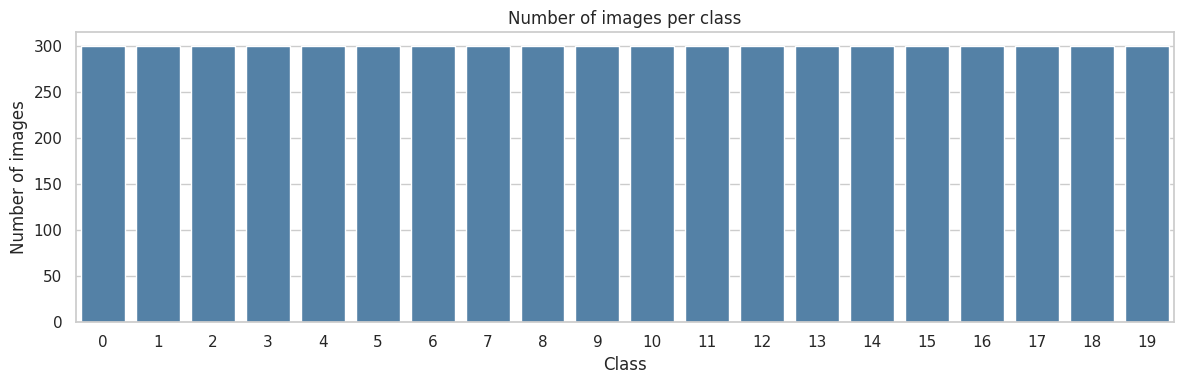

In [9]:
plt.figure(figsize=(12,4))
sns.countplot(data=df, x='label', color='steelblue')
plt.title("Number of images per class")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.tight_layout()
plt.savefig("results/class_distribution.png", dpi=120)
plt.show()

**✅ What you see:** every bar is the same height, **300 images per class**, so the dataset is **perfectly balanced**. Accuracy is therefore a fair score, and we don't need class weights.

### 4.2 Image size, colour mode, broken files and duplicates
We add new columns to `df` for each image's width, height and colour mode, whether it opens correctly, and a "fingerprint" (MD5 hash) used to find exact duplicates.

In [10]:
def image_info(path):
  # Open one image and return its properties (or mark it as broken)
  try:
    with Image.open(path) as img:
      img.load()
      return pd.Series({"width": img.width, "height": img.height, "mode": img.mode, "readable": True})
  except Exception:
    return pd.Series({"width": None, "height": None, "mode": None, "readable": False})

df[["width", "height", "mode", "readable"]] = df["filepath"].apply(image_info)
df["md5"] = df["filepath"].apply(lambda p: hashlib.md5(open(p, "rb").read()).hexdigest())

df.head()

,filepath,filename,label,frame,width,height,mode,readable,md5
0,dataset/test/0/901.jpg,901.jpg,0,901,50,50,L,True,aea9ea31ef8a4c922d818f8525d2ec59
1,dataset/test/0/902.jpg,902.jpg,0,902,50,50,L,True,9b5dbbd757bdb64eb1cff0f7c8b67ef7
2,dataset/test/0/903.jpg,903.jpg,0,903,50,50,L,True,75238b5f2843b03349f6bf8faa927d75
3,dataset/test/0/904.jpg,904.jpg,0,904,50,50,L,True,875986d9d6de18acc31b181251794fa7
4,dataset/test/0/905.jpg,905.jpg,0,905,50,50,L,True,c3ae2c6a1c099c355663f7c961f6399a


In [11]:
# One clear summary table of the whole dataset
non_null_modes = [m for m in df["mode"].unique() if m is not None]

summary = pd.DataFrame({
    "Value": [
        len(df),
        df["label"].nunique(),
        f'{df["label"].value_counts().min()} to {df["label"].value_counts().max()}',
        ", ".join(df["filename"].str.split(".").str[-1].unique()),
        ", ".join(f"{w}×{h}" for w, h in df[["width", "height"]].dropna().drop_duplicates().values),
        ", ".join(non_null_modes) + "  (L = grayscale)" if non_null_modes else "None",
        int((~df["readable"]).sum()),
        int(df["md5"].duplicated().sum()),
    ]},
    index=["Total images", "Number of classes", "Images per class", "File format",
           "Image size (pixels)", "Colour mode", "Broken / unreadable images", "Exact duplicate images"])
banner("📋 DATASET SUMMARY")
summary

══════════════════════════════════════════════════════════════════════
  📋 DATASET SUMMARY
══════════════════════════════════════════════════════════════════════


,Value
Total images,6000
Number of classes,20
Images per class,300 to 300
File format,jpg
Image size (pixels),50×50
Colour mode,L (L = grayscale)
Broken / unreadable images,0
Exact duplicate images,0


**✅ What you see (from our run):** 6,000 JPG images in 20 classes, all **50×50 pixels** and **grayscale** (`L`), with **0 broken** images and **0 duplicates**.

**Why this matters:**
- VGG16 was trained on **colour (RGB)** photos, so we will convert gray → RGB (the same gray value copied into 3 channels).
- 50×50 is very small. We will enlarge the images to 96×96 so they pass through VGG16's 5 pooling steps.

---
## 🟦 Step 5: Look at the images
### 5.1 One example image from each class

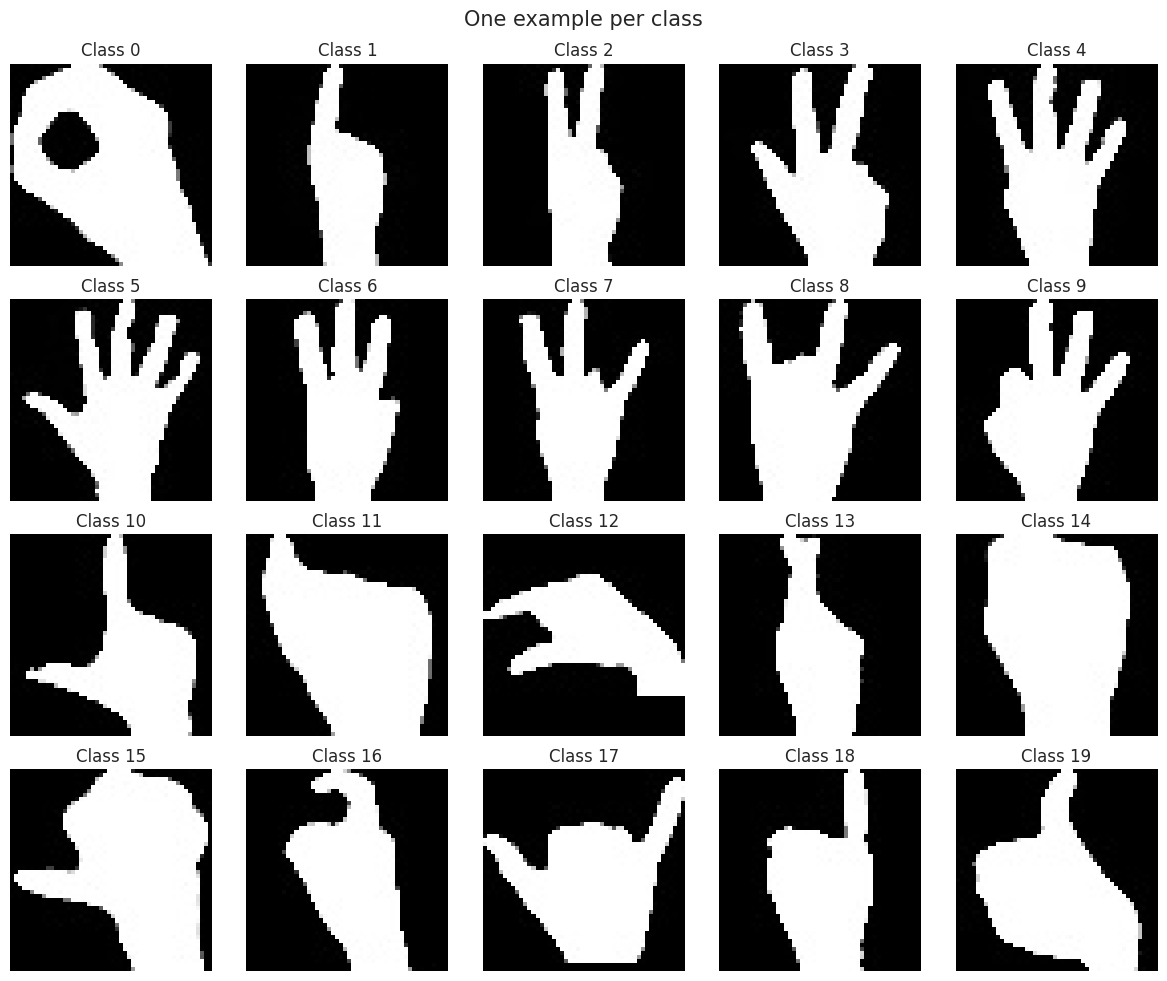

In [12]:
examples = df.groupby("label").first()          # first row of each class
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for ax, (label, row) in zip(axes.flat, examples.iterrows()):
    ax.imshow(Image.open(row["filepath"]), cmap="gray")
    ax.set_title(f"Class {label}", fontsize=12)
    ax.axis("off")
plt.suptitle("One example per class", fontsize=15)
plt.tight_layout(); plt.savefig("results/sample_images.png", dpi=120); plt.show()

**✅ What you see:** white **hand shapes on a black background**, a different gesture for each class. The images have no colour or background, so the **shape of the hand** is the only clue the model can use. Some classes look alike (similar finger positions), and these may get confused later.

### 5.2 Images from one class in file order

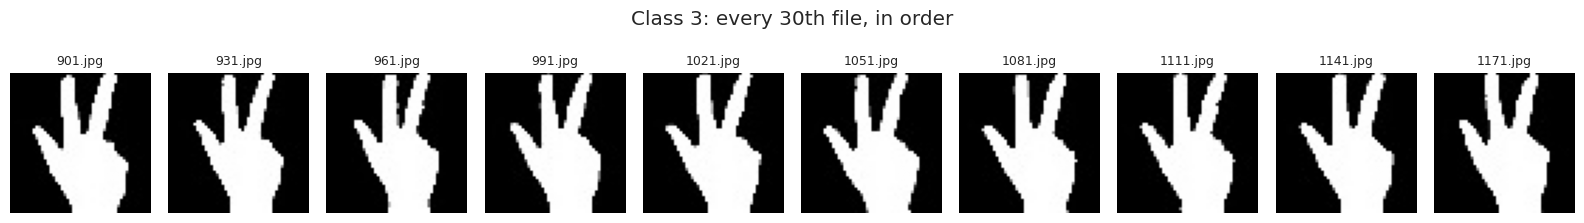

In [13]:
one_class = df[df["label"] == 3]                  # all rows of class 3
picks = one_class.iloc[::30]                      # every 30th image
fig, axes = plt.subplots(1, len(picks), figsize=(16, 2.4))
for ax, (_, row) in zip(axes, picks.iterrows()):
    ax.imshow(Image.open(row["filepath"]), cmap="gray")
    ax.set_title(row["filename"], fontsize=9); ax.axis("off")
plt.suptitle("Class 3: every 30th file, in order"); plt.tight_layout(); plt.show()

### 5.3 Are neighbouring files almost the same picture?
We compare each image with the **next** file and with a file **far away** in the same class. A small difference means the images look alike.

In [14]:
def load_gray(path):
    return np.array(Image.open(path), dtype=float) / 255      # pixel values 0..1

similarity = []
for label, group in df.groupby("label"):
    imgs = [load_gray(p) for p in group["filepath"]]
    n = len(imgs)
    next_diff = np.mean([np.abs(imgs[i] - imgs[i + 1]).mean() for i in range(n - 1)])
    far_diff = np.mean([np.abs(imgs[i] - imgs[(i + n // 2) % n]).mean() for i in range(n)])
    similarity.append({"label": label, "difference to NEXT file": next_diff, "difference to FAR file": far_diff})

similarity = pd.DataFrame(similarity).set_index("label")
ratio = similarity["difference to FAR file"].mean() / similarity["difference to NEXT file"].mean()
banner(f"Neighbouring files are {ratio:.1f}x more similar than far-apart files")
similarity.T.style.format("{:.3f}").background_gradient(cmap="Oranges", axis=1)

══════════════════════════════════════════════════════════════════════
  Neighbouring files are 4.5x more similar than far-apart files
══════════════════════════════════════════════════════════════════════


label,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
difference to NEXT file,0.021,0.010,0.010,0.015,0.020,0.022,0.016,0.015,0.017,0.012,0.012,0.016,0.014,0.010,0.017,0.025,0.013,0.016,0.014,0.013
difference to FAR file,0.303,0.056,0.037,0.069,0.087,0.177,0.057,0.081,0.069,0.071,0.032,0.030,0.024,0.026,0.071,0.048,0.030,0.036,0.043,0.035


**✅ What you see:** neighbouring files are about **4.5× more similar** than far-apart ones, because the images are **frames from a video**.

**💡 Why this is important:** if we split the images **randomly**, the test set would contain near-copies of training images, and the score would look better than it really is. This is called **data leakage**. In Step 6 we split by **frame order** instead.

### 5.4 Pixel brightness histogram

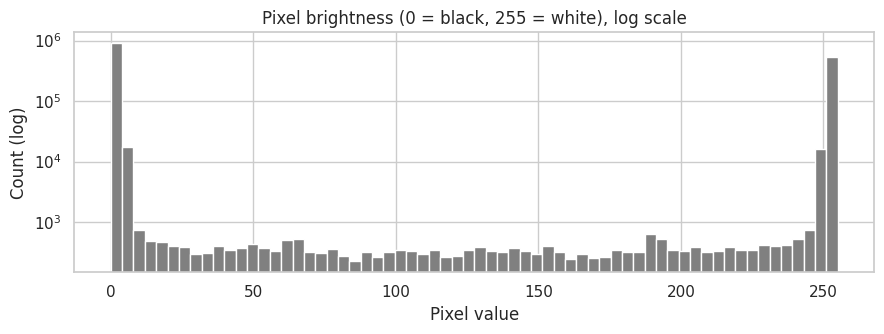

Black pixels: 61.6% | White pixels: 37.3% | In between: 1.1%


In [15]:
sample_pixels = np.concatenate([np.array(Image.open(p)).ravel() for p in df["filepath"].sample(600, random_state=42)])
plt.figure(figsize=(9, 3.5))
plt.hist(sample_pixels, bins=64, color="gray", log=True)
plt.title("Pixel brightness (0 = black, 255 = white), log scale")
plt.xlabel("Pixel value"); plt.ylabel("Count (log)")
plt.tight_layout(); plt.savefig("results/pixel_histogram.png", dpi=120); plt.show()
print(f"Black pixels: {(sample_pixels < 30).mean():.1%} | White pixels: {(sample_pixels > 225).mean():.1%} | "
      f"In between: {((sample_pixels >= 30) & (sample_pixels <= 225)).mean():.1%}")

**✅ What you see:** almost every pixel is either **black (0)** or **white (255)

**. The images are black-and-white masks. The few gray pixels are at the hand's edges.

---
## 🟦 Step 6: Split `df` into train / validation / test
**🎯 What we do:** within each class, use the file order to give every image a **split** name:

```
position in class:  0 ........ 209 | 210-214 | 215 .... 254 | 255-259 | 260 .... 299
split:              train (210)    |  gap    |  val (40)    |  gap    |  test (40)
```
**💡 Why:** test images come from a **different part of the video** than the training images, and the small **gaps** (unused frames) stop near-copies from crossing over. Every class gets the same numbers, so the split is **stratified**.

In [16]:
df["position"] = df.groupby("label").cumcount()      # 0, 1, 2, ... 299 inside each class (df is sorted by frame)

def which_split(position):
    if position < 210:
        return "train"
    elif 215 <= position < 255:
        return "val"
    elif position >= 260:
        return "test"
    else:
        return "gap (not used)"

df["split"] = df["position"].apply(which_split)

train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "val"]
test_df = df[df["split"] == "test"]

banner(f"✅ Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)} | "
       f"Gap: {(df['split'] == 'gap (not used)').sum()}")
split_table = pd.crosstab(df["split"], df["label"]).reindex(["train", "val", "test", "gap (not used)"])
split_table.style.background_gradient(cmap="Greens", axis=None)

══════════════════════════════════════════════════════════════════════
  ✅ Train: 4200 | Validation: 800 | Test: 800 | Gap: 200
══════════════════════════════════════════════════════════════════════


label,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
split,,,,,,,,,,,,,,,,,,,,
train,210,210,210,210,210,210,210,210,210,210,210,210,210,210,210,210,210,210,210,210
val,40,40,40,40,40,40,40,40,40,40,40,40,40,40,40,40,40,40,40,40
test,40,40,40,40,40,40,40,40,40,40,40,40,40,40,40,40,40,40,40,40
gap (not used),10,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10


In [17]:
# Safety check: no image is in two splits
assert len(set(train_df.filepath) & set(test_df.filepath)) == 0
assert len(set(train_df.filepath) & set(val_df.filepath)) == 0
assert len(set(val_df.filepath) & set(test_df.filepath)) == 0
print("✅ No overlap between train, validation and test")
df[["filename", "label", "frame", "position", "split"]].iloc[205:265:6]

✅ No overlap between train, validation and test


,filename,label,frame,position,split
205,1106.jpg,0,1106,205,train
211,1112.jpg,0,1112,211,gap (not used)
217,1118.jpg,0,1118,217,val
223,1124.jpg,0,1124,223,val
229,1130.jpg,0,1130,229,val
235,1136.jpg,0,1136,235,val
241,1142.jpg,0,1142,241,val
247,1148.jpg,0,1148,247,val
253,1154.jpg,0,1154,253,val
259,1160.jpg,0,1160,259,gap (not used)


**✅ What you see:** every class has **210 train, 40 validation and 40 test** images. The last table shows the split changing from `train` → `gap` → `val` → `gap` → `test` as the position goes up.

The **test set is not used until Step 11.** We make every decision with the validation set only.

---
## 🟦 Step 7: Load the images into arrays
**🎯 What we do:** open every image, convert gray → **RGB** (3 channels), and resize to **96×96**.
**💡 Why:** VGG16 expects 3-channel colour images. 96×96 is big enough for VGG16 (minimum 32×32) without wasting time, since the originals are only 50×50.

In [18]:
IMG_SIZE = 96

def load_images(paths):
    # Turn a list of file paths into one array of shape (number_of_images, 96, 96, 3)
    images = []
    for path in paths:
        img = Image.open(path).convert("RGB")                       # gray -> RGB (3 equal channels)
        img = img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)      # 50x50 -> 96x96
        images.append(np.array(img))
    return np.array(images)

X_train, y_train = load_images(train_df["filepath"]), train_df["label"].values
X_val, y_val = load_images(val_df["filepath"]), val_df["label"].values
X_test, y_test = load_images(test_df["filepath"]), test_df["label"].values

pd.DataFrame({
    "images array (X) shape": [X_train.shape, X_val.shape, X_test.shape],
    "labels (y) shape": [y_train.shape, y_val.shape, y_test.shape],
    "pixel range": [f"{X_train.min()}–{X_train.max()}", f"{X_val.min()}–{X_val.max()}", f"{X_test.min()}–{X_test.max()}"],
}, index=["train", "validation", "test"])

,images array (X) shape,labels (y) shape,pixel range
train,"(4200, 96, 96, 3)","(4200,)",0–255
validation,"(800, 96, 96, 3)","(800,)",0–255
test,"(800, 96, 96, 3)","(800,)",0–255


**✅ What you see:** `X_train` has shape `(4200, 96, 96, 3)`, which means 4,200

 images, each 96×96 with 3 colour channels. The labels are plain numbers 0–19.

---
## 🟦 Step 8: Build Model 1, VGG16 Feature Extraction
The model is a chain of blocks:

```
raw image (0-255) → augmentation → VGG16 preprocessing → VGG16 (FROZEN) → new head → 20 class probabilities
```

### 8.1 Data augmentation
**🎯 What:** small random **rotations, zooms and shifts** of the training images.
**💡 Why:** the model sees more variety and copes better with hands that move slightly. Augmentation is **only active during training**. Keras switches it off automatically for validation, testing and prediction.
**🚫 No left↔right flips:** a mirrored hand can be a different gesture.

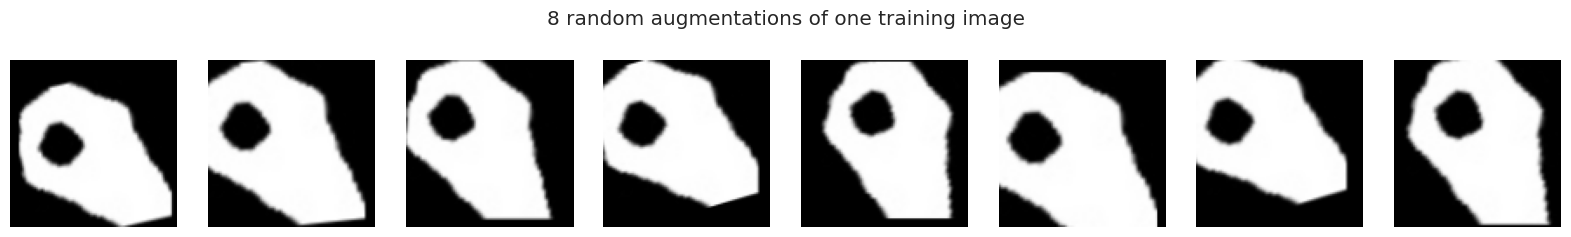

In [19]:
augmentation = keras.Sequential([
    layers.RandomRotation(0.05, fill_mode="constant"),            # rotate up to ±18°
    layers.RandomZoom(0.10, fill_mode="constant"),                # zoom in/out up to 10%
    layers.RandomTranslation(0.10, 0.10, fill_mode="constant"),   # shift up to 10%
], name="augmentation")

# Show 8 random augmented versions of the same image
same_image_8_times = np.repeat(X_train[:1], 8, axis=0).astype("float32")
augmented = augmentation(same_image_8_times, training=True).numpy().astype("uint8")
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, img in zip(axes, augmented):
    ax.imshow(img); ax.axis("off")
plt.suptitle("8 random augmentations of one training image"); plt.tight_layout(); plt.show()

### 8.2 VGG16 preprocessing
VGG16 needs its images prepared the same way as during its ImageNet training. The official function `vgg16.preprocess_input` does two things: it changes the channel order RGB → BGR, and it subtracts the average ImageNet colour `[103.939, 116.779, 123.68]`.

**Simple trick:** our images are gray (R = G = B), so changing the channel order does nothing. That means a Keras `Normalization` layer that subtracts the same averages gives **exactly the same result**. We put it **inside the model**, so later the model can take raw images directly. The check below proves the two methods match.

In [20]:
vgg_preprocess = layers.Normalization(mean=[103.939, 116.779, 123.68], variance=[1.0, 1.0, 1.0],
                                      name="vgg16_preprocess")

check = X_train[:16].astype("float32")
official = vgg16.preprocess_input(check.copy())
ours = vgg_preprocess(check).numpy()
print("Biggest difference between official and our preprocessing:", float(np.abs(official - ours).max()))
assert np.allclose(official, ours, atol=1e-3)
print("✅ Identical. Our layer does exactly what vgg16.preprocess_input does")

Biggest difference between official and our preprocessing: 0.0
✅ Identical. Our layer does exactly what vgg16.preprocess_input does


### 8.3 Load VGG16, freeze it, and add the new head
- `include_top=False` removes VGG16's original 1,000-class ImageNet head.
- `base.trainable = False` **freezes** all 14.7 million VGG16 weights.
- The new **head** has 20 outputs (one per class) with `softmax`, so the outputs are probabilities that add up to 1.

In [21]:
base = vgg16.VGG16(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False                                    # FREEZE the whole VGG16

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augmentation(inputs)                                  # only active while training
x = vgg_preprocess(x)                                     # same as vgg16.preprocess_input
x = base(x, training=False)                               # frozen VGG16 -> 3x3x512 features
x = layers.GlobalAveragePooling2D()(x)                    # 3x3x512 -> 512 numbers
x = layers.Dense(256, activation="relu")(x)               # new layer 1
x = layers.Dropout(0.5)(x)                                # randomly switch off 50% (reduces overfitting)
outputs = layers.Dense(20, activation="softmax")(x)       # new layer 2: 20 class probabilities
model_fe = keras.Model(inputs, outputs, name="VGG16_feature_extraction")

model_fe.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                 loss="sparse_categorical_crossentropy",   # labels are numbers 0-19
                 metrics=["accuracy"])
model_fe.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "VGG16_feature_extraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16_preprocess                │ (None, 96, 96, 3)      │             0 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         5,140 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,851,156 (56.65 MB)

 Trainable params: 136,468 (533.08 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [22]:
def count_parameters(model):
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    frozen = int(sum(np.prod(w.shape) for w in model.non_trainable_weights))
    return trainable, frozen

trainable, frozen = count_parameters(model_fe)
pd.DataFrame({"parameters": [f"{trainable:,}", f"{frozen:,}"],
              "meaning": ["NEW head: will be trained", "VGG16: frozen, keeps its ImageNet knowledge"]},
             index=["trainable", "frozen"])

,parameters,meaning
trainable,"136,468",NEW head: will be trained
frozen,"14,714,688","VGG16: frozen, keeps its ImageNet knowledge"


**✅ What you see:** only **136,468** parameters are trainable (the new head), while **14.7 million** VGG16 parameters stay frozen. Training the small head is fast and protects VGG16's knowledge.

---
## 🟦 Step 9: Train Model 1
**Settings:**

| Setting | Value | Why |
|---|---|---|
| epochs | up to 10 | one epoch = the model sees every training image once |
| batch size | 32 | images per weight update; fits easily in GPU memory |
| learning rate | 0.001 | normal size of steps for a new head |
| EarlyStopping | patience 3 | stop if the validation loss stops improving |
| ModelCheckpoint | best val_loss | always keep the best version on disk |
| ReduceLROnPlateau | ×0.2 after 2 bad epochs | take smaller steps when progress stalls |

In [23]:
EPOCHS_FE = 10

def make_callbacks(save_path):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ModelCheckpoint(save_path, monitor="val_loss", save_best_only=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, verbose=1),
    ]

start = time.time()
history_fe = model_fe.fit(X_train, y_train, validation_data=(X_val, y_val),
                          epochs=EPOCHS_FE, batch_size=32, verbose=2,
                          callbacks=make_callbacks("models/vgg16_feature_extraction.keras"))
time_fe = time.time() - start

model_fe = keras.models.load_model("models/vgg16_feature_extraction.keras")    # reload the BEST epoch
banner(f"✅ Model 1 trained in {time_fe / 60:.1f} minutes")

Epoch 1/10
132/132 - 14s - 109ms/step - accuracy: 0.6974 - loss: 1.4632 - val_accuracy: 0.9488 - val_loss: 0.1718 - learning_rate: 0.0010
Epoch 2/10
132/132 - 5s - 39ms/step - accuracy: 0.9233 - loss: 0.2300 - val_accuracy: 0.9638 - val_loss: 0.0959 - learning_rate: 0.0010
Epoch 3/10
132/132 - 4s - 33ms/step - accuracy: 0.9571 - loss: 0.1333 - val_accuracy: 0.9500 - val_loss: 0.1183 - learning_rate: 0.0010
Epoch 4/10
132/132 - 5s - 36ms/step - accuracy: 0.9586 - loss: 0.1258 - val_accuracy: 0.9800 - val_loss: 0.0551 - learning_rate: 0.0010
Epoch 5/10
132/132 - 5s - 40ms/step - accuracy: 0.9760 - loss: 0.0771 - val_accuracy: 0.9750 - val_loss: 0.0548 - learning_rate: 0.0010
Epoch 6/10
132/132 - 4s - 34ms/step - accuracy: 0.9779 - loss: 0.0677 - val_accuracy: 0.9513 - val_loss: 0.1344 - learning_rate: 0.0010
Epoch 7/10

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
132/132 - 4s - 34ms/step - accuracy: 0.9817 - loss: 0.0528 - val_accuracy: 0.9538 - val_loss:

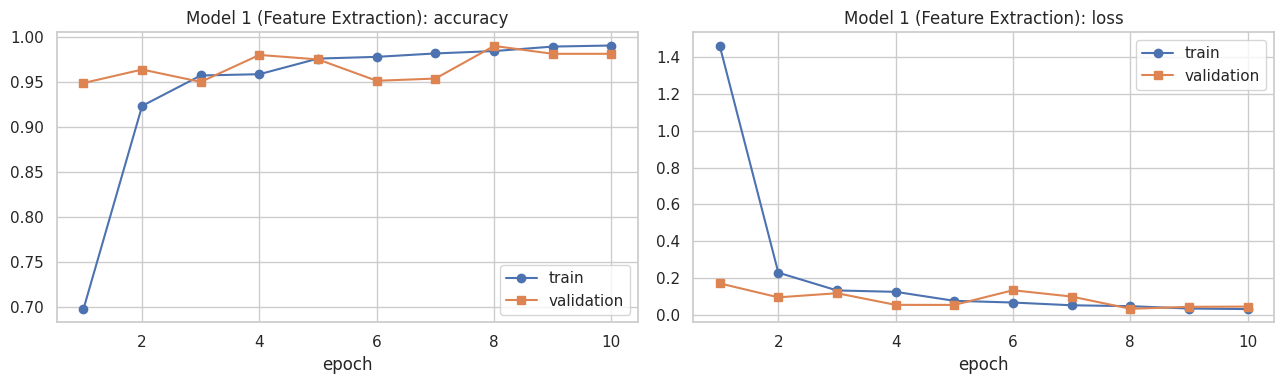

,accuracy,val_accuracy,loss,val_loss
epoch,,,,
1,0.6974,0.9488,1.4632,0.1718
2,0.9233,0.9638,0.2300,0.0959
3,0.9571,0.9500,0.1333,0.1183
4,0.9586,0.9800,0.1258,0.0551
5,0.9760,0.9750,0.0771,0.0548
6,0.9779,0.9513,0.0677,0.1344
7,0.9817,0.9538,0.0528,0.1002
8,0.9843,0.9900,0.0479,0.0337
9,0.9893,0.9812,0.0351,0.0444


In [24]:
def show_history(history, title, filename):
    hist = pd.DataFrame(history.history)
    hist.index = hist.index + 1
    hist.index.name = "epoch"
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    ax1.plot(hist["accuracy"], "o-", label="train"); ax1.plot(hist["val_accuracy"], "s-", label="validation")
    ax1.set_title(f"{title}: accuracy"); ax1.set_xlabel("epoch"); ax1.legend()
    ax2.plot(hist["loss"], "o-", label="train"); ax2.plot(hist["val_loss"], "s-", label="validation")
    ax2.set_title(f"{title}: loss"); ax2.set_xlabel("epoch"); ax2.legend()
    plt.tight_layout(); plt.savefig(f"results/{filename}", dpi=120); plt.show()
    return hist[["accuracy", "val_accuracy", "loss", "val_loss"]].style.format("{:.4f}") \
        .background_gradient(cmap="Greens", subset=["accuracy", "val_accuracy"]) \
        .background_gradient(cmap="Reds_r", subset=["loss", "val_loss"])

show_history(history_fe, "Model 1 (Feature Extraction)", "history_feature_extraction.png")

**📖 How to read the curves:**
- ✅ **Good:** both losses go down and flatten, and the train and validation lines stay close.
- ⚠️ **Overfitting:** train accuracy keeps rising but validation accuracy stops or drops (memorising instead of learning).
- ⚠️ **Underfitting:** both accuracies are still low.
- ℹ️ Train accuracy can be a bit **lower** than validation at the start, because augmentation and dropout make training harder on purpose. That is normal.

---
## 🟦 Step 10: Model 2, VGG16 Fine-Tuning
**🎯 What we do:** take the trained Model 1, **unfreeze only VGG16's last block (`block5`)**, and train again with a **100× smaller learning rate** (0.00001).

**💡 Why:**
- Lower blocks find simple things (edges, corners) that are useful for any image, so we keep them frozen.
- `block5` finds ImageNet-specific shapes. Adapting it to hand shapes can improve accuracy.
- A **tiny learning rate** makes small, careful changes, so VGG16 doesn't "forget" what it learned (*catastrophic forgetting*).
- We **must compile again** after changing which layers are trainable, or the change has no effect.

In [25]:
model_ft = keras.models.load_model("models/vgg16_feature_extraction.keras")   # a separate copy of Model 1
vgg_inside = model_ft.get_layer("vgg16")

vgg_inside.trainable = True                                 # allow training...
for layer in vgg_inside.layers:
    layer.trainable = layer.name.startswith("block5")      # ...but only for block5 layers

layer_table = pd.DataFrame({"layer": [l.name for l in vgg_inside.layers],
                            "trainable": [l.trainable for l in vgg_inside.layers]})
layer_table.style.map(lambda v: "background-color: #b6e3b6" if v is True else "", subset=["trainable"])

,layer,trainable
0,input_layer_1,False
1,block1_conv1,False
2,block1_conv2,False
3,block1_pool,False
4,block2_conv1,False
5,block2_conv2,False
6,block2_pool,False
7,block3_conv1,False
8,block3_conv2,False
9,block3_conv3,False


══════════════════════════════════════════════════════════════════════
  Trainable parameters now: 7,215,892  (block5 + head) | frozen: 7,635,264
══════════════════════════════════════════════════════════════════════
Epoch 1/8
132/132 - 11s - 82ms/step - accuracy: 0.9917 - loss: 0.0248 - val_accuracy: 0.9962 - val_loss: 0.0131 - learning_rate: 1.0000e-05
Epoch 2/8
132/132 - 7s - 51ms/step - accuracy: 0.9929 - loss: 0.0199 - val_accuracy: 0.9987 - val_loss: 0.0055 - learning_rate: 1.0000e-05
Epoch 3/8
132/132 - 6s - 46ms/step - accuracy: 0.9931 - loss: 0.0211 - val_accuracy: 0.9950 - val_loss: 0.0124 - learning_rate: 1.0000e-05
Epoch 4/8
132/132 - 7s - 53ms/step - accuracy: 0.9981 - loss: 0.0066 - val_accuracy: 1.0000 - val_loss: 0.0012 - learning_rate: 1.0000e-05
Epoch 5/8
132/132 - 6s - 47ms/step - accuracy: 0.9981 - loss: 0.0044 - val_accuracy: 1.0000 - val_loss: 0.0013 - learning_rate: 1.0000e-05
Epoch 6/8
132/132 - 7s - 52ms/step - accuracy: 0.9990 - loss: 0.0041 - val_accuracy: 1.

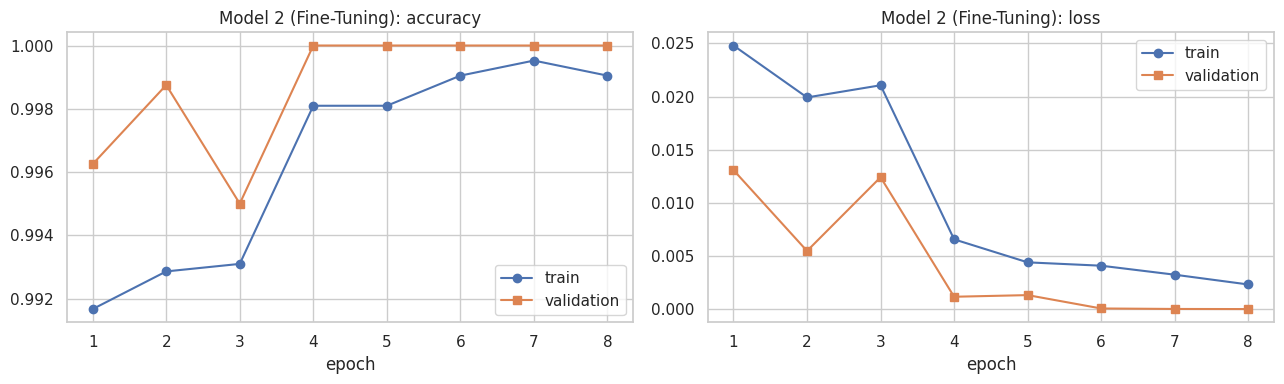

,accuracy,val_accuracy,loss,val_loss
epoch,,,,
1,0.9917,0.9962,0.0248,0.0131
2,0.9929,0.9987,0.0199,0.0055
3,0.9931,0.9950,0.0211,0.0124
4,0.9981,1.0000,0.0066,0.0012
5,0.9981,1.0000,0.0044,0.0013
6,0.9990,1.0000,0.0041,0.0001
7,0.9995,1.0000,0.0032,0.0000
8,0.9990,1.0000,0.0023,0.0000


In [26]:
model_ft.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),   # 100x smaller than before
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
trainable_ft, frozen_ft = count_parameters(model_ft)
banner(f"Trainable parameters now: {trainable_ft:,}  (block5 + head) | frozen: {frozen_ft:,}")

EPOCHS_FT = 8
start = time.time()
history_ft = model_ft.fit(X_train, y_train, validation_data=(X_val, y_val),
                          epochs=EPOCHS_FT, batch_size=32, verbose=2,
                          callbacks=make_callbacks("models/vgg16_fine_tuning.keras"))
time_ft = time_fe + (time.time() - start)        # fine-tuning needed Model 1 first, so add its time

model_ft = keras.models.load_model("models/vgg16_fine_tuning.keras")   # reload the BEST epoch
banner(f"✅ Model 2 trained | total time incl. Model 1: {time_ft / 60:.1f} minutes")
show_history(history_ft, "Model 2 (Fine-Tuning)", "history_fine_tuning.png")

**✅ What you see:** green `True` only for `block5_conv1`, `block5_conv2`, `block5_conv3` and `block5_pool`, and about **7.2 million** trainable parameters. Compare the validation accuracy here with Model 1's best value. If it went up, fine-tuning helped.

---
## 🟦 Step 11: Test both models (the "final exam")
**🎯 What we do:** use the **800 test images** that no model has seen yet.
**💡 Why:** we used the validation set to pick the best epochs, so its score is slightly optimistic. The test score is the honest one.

**Macro average:** calculate precision, recall and F1 for each class, then take the average, so every class counts equally.

In [27]:
def evaluate(model, name):
    probabilities = model.predict(X_test, verbose=0)       # 20 probabilities per image
    predictions = probabilities.argmax(axis=1)              # class with the highest probability
    _, train_acc = model.evaluate(X_train, y_train, verbose=0)
    _, val_acc = model.evaluate(X_val, y_val, verbose=0)
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, predictions, average="macro")
    scores = {"Training accuracy": train_acc, "Validation accuracy": val_acc, "Test accuracy": test_acc,
              "Precision (macro)": precision, "Recall (macro)": recall, "F1-score (macro)": f1,
              "Test loss": test_loss, "Wrong test images": int((predictions != y_test).sum())}
    return probabilities, predictions, scores

probs_fe, preds_fe, scores_fe = evaluate(model_fe, "Feature Extraction")
probs_ft, preds_ft, scores_ft = evaluate(model_ft, "Fine-Tuning")

banner("🧪 TEST RESULTS")
pd.DataFrame({"Model 1: Feature Extraction": scores_fe, "Model 2: Fine-Tuning": scores_ft}).style.format("{:.4f}") \
  .format("{:.0f}", subset=pd.IndexSlice[["Wrong test images"], :])

══════════════════════════════════════════════════════════════════════
  🧪 TEST RESULTS
══════════════════════════════════════════════════════════════════════


,Model 1: Feature Extraction,Model 2: Fine-Tuning
Training accuracy,0.9940,0.9998
Validation accuracy,0.9900,1.0000
Test accuracy,0.9850,0.9987
Precision (macro),0.9872,0.9988
Recall (macro),0.9850,0.9988
F1-score (macro),0.9852,0.9987
Test loss,0.0457,0.0020
Wrong test images,12,1


In [28]:
# Classification report as a table (per class), here for Model 2
report_ft = pd.DataFrame(classification_report(y_test, preds_ft, output_dict=True)).T
banner("📊 Per-class report: Model 2 (Fine-Tuning)")
report_ft.style.format("{:.3f}").background_gradient(cmap="RdYlGn", subset=["precision", "recall", "f1-score"], vmin=0.7, vmax=1)

══════════════════════════════════════════════════════════════════════
  📊 Per-class report: Model 2 (Fine-Tuning)
══════════════════════════════════════════════════════════════════════


,precision,recall,f1-score,support
0,1.000,1.000,1.000,40.000
1,1.000,1.000,1.000,40.000
2,1.000,1.000,1.000,40.000
3,1.000,1.000,1.000,40.000
4,1.000,1.000,1.000,40.000
5,1.000,1.000,1.000,40.000
6,0.976,1.000,0.988,40.000
7,1.000,1.000,1.000,40.000
8,1.000,1.000,1.000,40.000
9,1.000,0.975,0.987,40.000


In [29]:
# Same per-class report for Model 1
report_fe = pd.DataFrame(classification_report(y_test, preds_fe, output_dict=True)).T
banner("📊 Per-class report: Model 1 (Feature Extraction)")
report_fe.style.format("{:.3f}").background_gradient(cmap="RdYlGn", subset=["precision", "recall", "f1-score"], vmin=0.7, vmax=1)

══════════════════════════════════════════════════════════════════════
  📊 Per-class report: Model 1 (Feature Extraction)
══════════════════════════════════════════════════════════════════════


,precision,recall,f1-score,support
0,1.000,1.000,1.000,40.000
1,1.000,1.000,1.000,40.000
2,1.000,1.000,1.000,40.000
3,1.000,1.000,1.000,40.000
4,1.000,0.850,0.919,40.000
5,1.000,1.000,1.000,40.000
6,0.816,1.000,0.899,40.000
7,1.000,0.950,0.974,40.000
8,0.976,1.000,0.988,40.000
9,1.000,0.925,0.961,40.000


In [30]:
# Same per-class report for Model 1
report_fe = pd.DataFrame(classification_report(y_test, preds_fe, output_dict=True)).T
banner("📊 Per-class report: Model 1 (Feature Extraction)")
report_fe.style.format("{:.3f}").background_gradient(cmap="RdYlGn", subset=["precision", "recall", "f1-score"], vmin=0.7, vmax=1)

══════════════════════════════════════════════════════════════════════
  📊 Per-class report: Model 1 (Feature Extraction)
══════════════════════════════════════════════════════════════════════


,precision,recall,f1-score,support
0,1.000,1.000,1.000,40.000
1,1.000,1.000,1.000,40.000
2,1.000,1.000,1.000,40.000
3,1.000,1.000,1.000,40.000
4,1.000,0.850,0.919,40.000
5,1.000,1.000,1.000,40.000
6,0.816,1.000,0.899,40.000
7,1.000,0.950,0.974,40.000
8,0.976,1.000,0.988,40.000
9,1.000,0.925,0.961,40.000


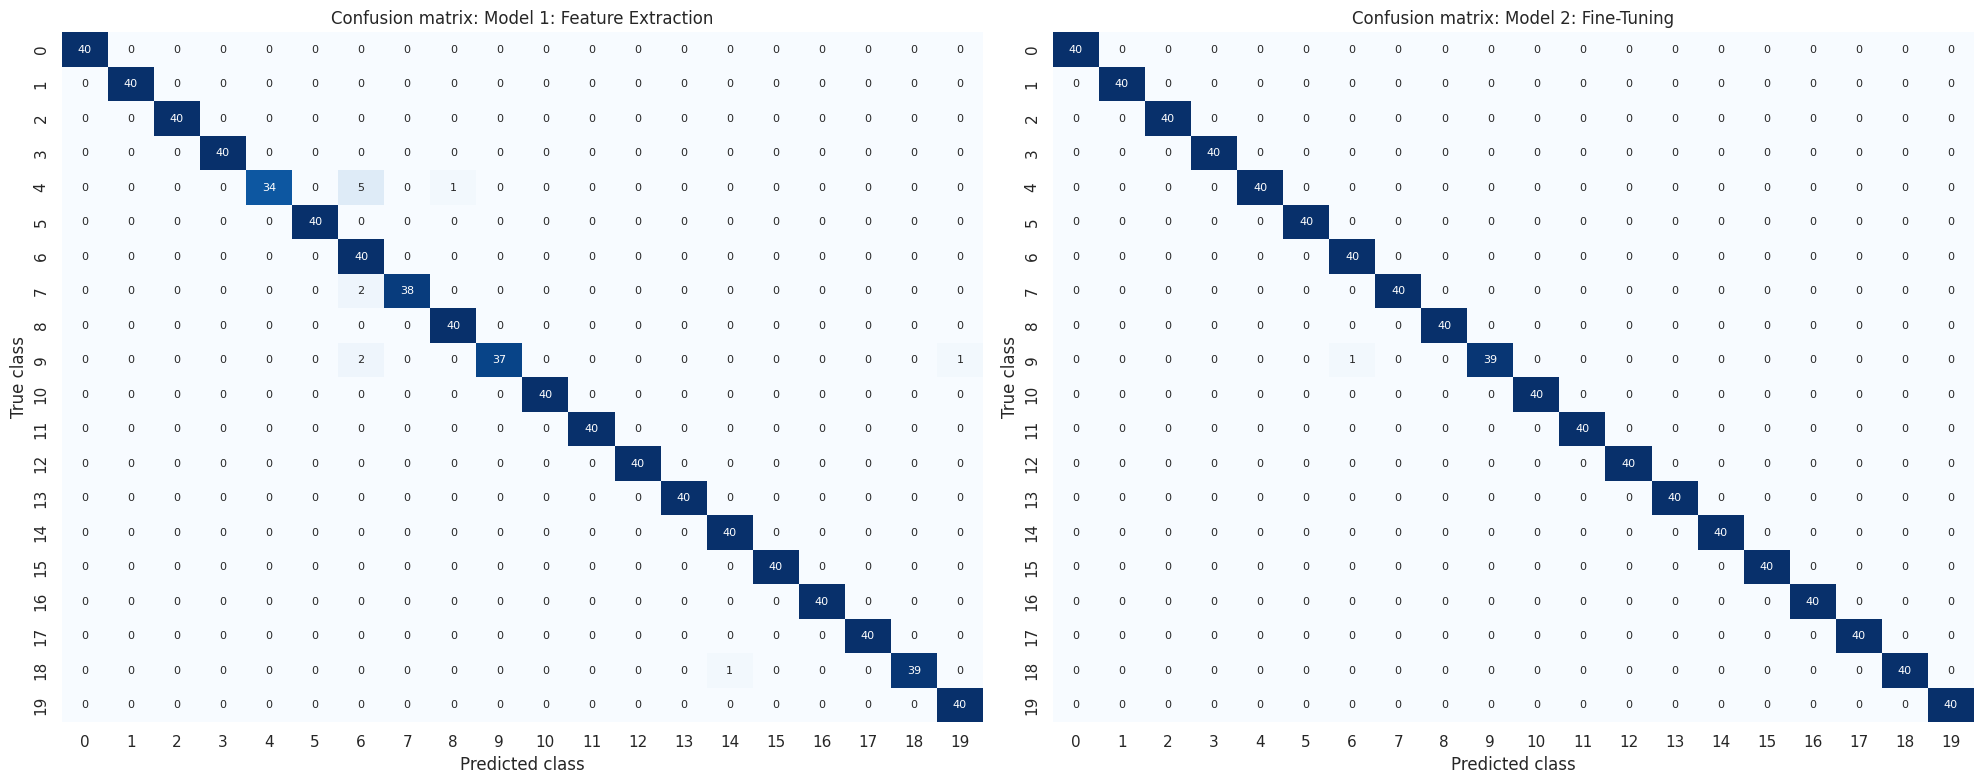

In [31]:
# Confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, preds, title in [(axes[0], preds_fe, "Model 1: Feature Extraction"), (axes[1], preds_ft, "Model 2: Fine-Tuning")]:
    sns.heatmap(confusion_matrix(y_test, preds), annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                annot_kws={"size": 8})
    ax.set_title(f"Confusion matrix: {title}"); ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
plt.tight_layout(); plt.savefig("results/confusion_matrices.png", dpi=120); plt.show()

**📖 How to read a confusion matrix:** rows = the **true** class, columns = the **predicted** class.

A perfect model has **40 on the diagonal** and 0 everywhere else. Any number off the diagonal is a mistake.

For example, row 7 / column 8 = "class 7 images that were predicted as class 8".

---
## 🟦 Step 12: Find the wrong predictions
**🎯 What we do:** make a table `pred_df` (built from `test_df`) with the true class and **each model's prediction and confidence** for every test image. Then we filter the wrong ones.
**💡 Why:** the scores show *how often* a model is wrong, and the pictures show *why*.

In [32]:
# The best model is chosen with the VALIDATION accuracy (never with the test set)
if scores_ft["Validation accuracy"] >= scores_fe["Validation accuracy"]:
    best_name, best_model = "Fine-Tuning", model_ft
else:
    best_name, best_model = "Feature Extraction", model_fe
banner(f"🏆 Best model on validation: {best_name}")

pred_df = test_df[["filepath", "filename", "label"]].copy()
pred_df["pred_FE"] = preds_fe                      # Model 1 prediction
pred_df["conf_FE"] = probs_fe.max(axis=1)          # Model 1 confidence (highest probability)
pred_df["pred_FT"] = preds_ft                      # Model 2 prediction
pred_df["conf_FT"] = probs_ft.max(axis=1)          # Model 2 confidence
pred_df["FE_correct"] = pred_df["label"] == pred_df["pred_FE"]
pred_df["FT_correct"] = pred_df["label"] == pred_df["pred_FT"]
pred_df.head(8).style.format({"conf_FE": "{:.1%}", "conf_FT": "{:.1%}"})

══════════════════════════════════════════════════════════════════════
  🏆 Best model on validation: Fine-Tuning
══════════════════════════════════════════════════════════════════════


,filepath,filename,label,pred_FE,conf_FE,pred_FT,conf_FT,FE_correct,FT_correct
260,dataset/test/0/1161.jpg,1161.jpg,0,0,100.0%,0,100.0%,True,True
261,dataset/test/0/1162.jpg,1162.jpg,0,0,100.0%,0,100.0%,True,True
262,dataset/test/0/1163.jpg,1163.jpg,0,0,100.0%,0,100.0%,True,True
263,dataset/test/0/1164.jpg,1164.jpg,0,0,100.0%,0,100.0%,True,True
264,dataset/test/0/1165.jpg,1165.jpg,0,0,100.0%,0,100.0%,True,True
265,dataset/test/0/1166.jpg,1166.jpg,0,0,100.0%,0,100.0%,True,True
266,dataset/test/0/1167.jpg,1167.jpg,0,0,100.0%,0,100.0%,True,True
267,dataset/test/0/1168.jpg,1168.jpg,0,0,100.0%,0,100.0%,True,True


In [33]:
# How many wrong per model, and how confident were they?
error_summary = pd.DataFrame({
    "wrong images": [(~pred_df.FE_correct).sum(), (~pred_df.FT_correct).sum()],
    "avg confidence when RIGHT": [pred_df[pred_df.FE_correct].conf_FE.mean(), pred_df[pred_df.FT_correct].conf_FT.mean()],
    "avg confidence when WRONG": [pred_df[~pred_df.FE_correct].conf_FE.mean(), pred_df[~pred_df.FT_correct].conf_FT.mean()],
}, index=["Model 1: Feature Extraction", "Model 2: Fine-Tuning"])
banner("❌ WRONG PREDICTIONS ON THE TEST SET")
error_summary.style.format({"avg confidence when RIGHT": "{:.1%}", "avg confidence when WRONG": "{:.1%}"}, na_rep="– (no errors)")

══════════════════════════════════════════════════════════════════════
  ❌ WRONG PREDICTIONS ON THE TEST SET
══════════════════════════════════════════════════════════════════════


,wrong images,avg confidence when RIGHT,avg confidence when WRONG
Model 1: Feature Extraction,12,97.8%,59.4%
Model 2: Fine-Tuning,1,100.0%,72.8%


Model 1 (Feature Extraction): most common mix-ups (true → predicted):
label  pred_FE
4      6          5
7      6          2
9      6          2
4      8          1
9      19         1
18     14         1


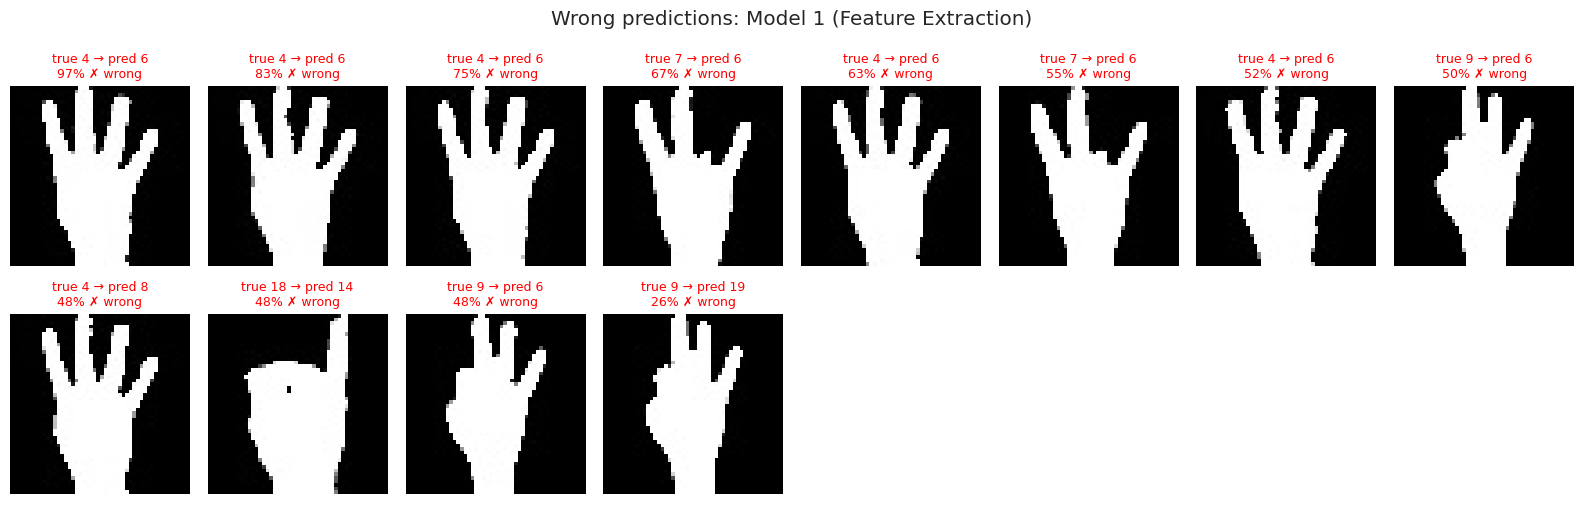

Model 2 (Fine-Tuning): most common mix-ups (true → predicted):
label  pred_FT
9      6          1


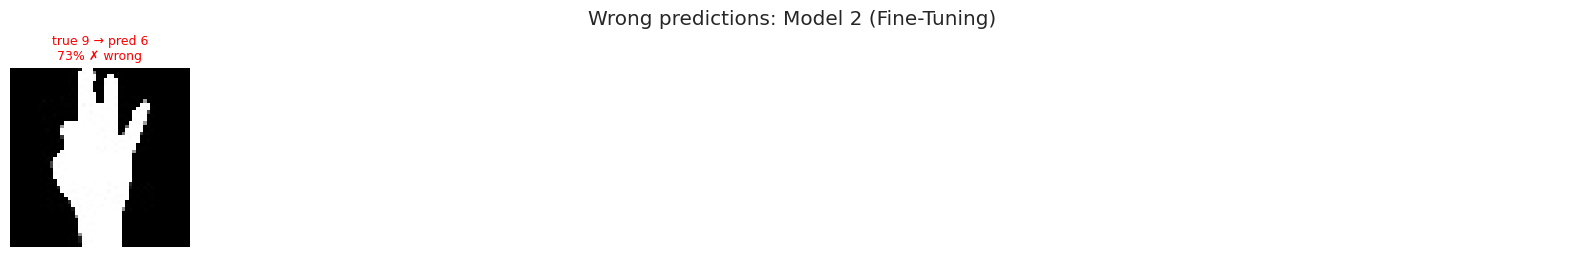

In [34]:
def show_wrong(pred_col, conf_col, correct_col, title, filename):
    wrong = pred_df[~pred_df[correct_col]].sort_values(conf_col, ascending=False)
    if len(wrong) == 0:
        print(f"🎉 {title}: no wrong test images at all!")
        return
    print(f"{title}: most common mix-ups (true → predicted):")
    print(wrong.groupby(["label", pred_col]).size().sort_values(ascending=False).rename("count").to_string())
    show = wrong.head(16)
    cols = 8
    rows = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(16, 2.7 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, row) in zip(axes.flat, show.iterrows()):
        ax.imshow(Image.open(row["filepath"]), cmap="gray")
        ax.set_title(f"true {row['label']} → pred {row[pred_col]}\n{row[conf_col]:.0%} ✗ wrong", color="red", fontsize=9)
    plt.suptitle(f"Wrong predictions: {title}")
    plt.tight_layout(); plt.savefig(f"results/{filename}", dpi=120); plt.show()

show_wrong("pred_FE", "conf_FE", "FE_correct", "Model 1 (Feature Extraction)", "wrong_feature_extraction.png")
show_wrong("pred_FT", "conf_FT", "FT_correct", "Model 2 (Fine-Tuning)", "wrong_fine_tuning.png")

In [35]:
# Images that Model 1 got WRONG but Model 2 FIXED
fixed = pred_df[~pred_df.FE_correct & pred_df.FT_correct]
print(f"✅ Fine-tuning fixed {len(fixed)} images that feature extraction got wrong")
fixed[["filename", "label", "pred_FE", "conf_FE", "pred_FT", "conf_FT"]].head(16) \
    .style.format({"conf_FE": "{:.1%}", "conf_FT": "{:.1%}"})

✅ Fine-tuning fixed 12 images that feature extraction got wrong


,filename,label,pred_FE,conf_FE,pred_FT,conf_FT
1463,1164.jpg,4,6,51.8%,4,100.0%
1464,1165.jpg,4,6,83.3%,4,100.0%
1475,1176.jpg,4,8,48.5%,4,100.0%
1483,1184.jpg,4,6,63.5%,4,100.0%
1485,1186.jpg,4,6,75.4%,4,100.0%
1490,1191.jpg,4,6,96.9%,4,99.9%
2365,1166.jpg,7,6,66.6%,7,100.0%
2366,1167.jpg,7,6,55.0%,7,100.0%
2991,1192.jpg,9,6,48.0%,9,95.7%
2996,1197.jpg,9,19,25.5%,9,98.5%


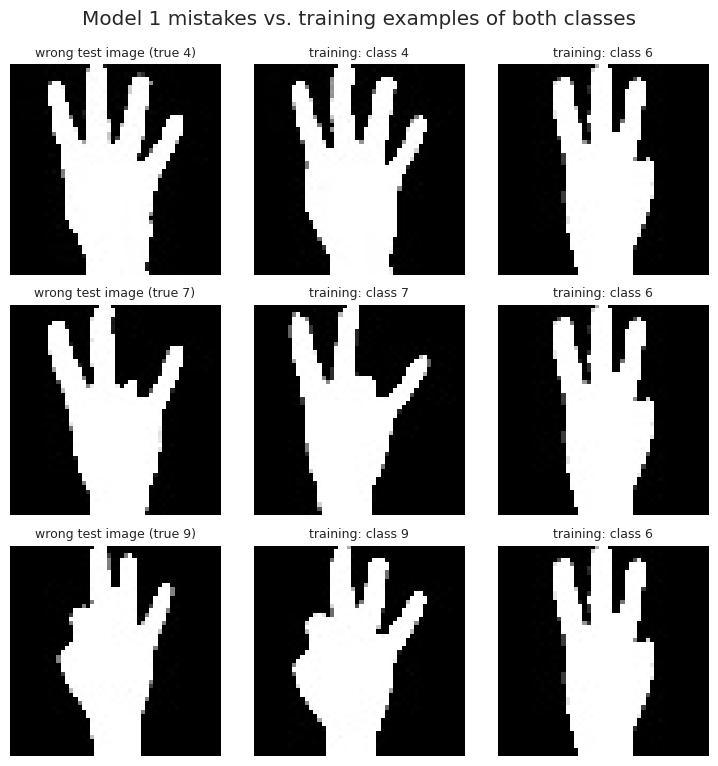

In [36]:
# Visual check: a wrong image next to typical TRAINING images of its true class and of the predicted class
wrong_any = pred_df[~pred_df.FE_correct].sort_values("conf_FE", ascending=False)
if len(wrong_any):
    pairs = wrong_any.groupby(["label", "pred_FE"]).size().sort_values(ascending=False).index[:3]
    fig, axes = plt.subplots(len(pairs), 3, figsize=(7.5, 2.6 * len(pairs)), squeeze=False)
    for r, (true_c, pred_c) in enumerate(pairs):
        wrong_img = wrong_any[(wrong_any.label == true_c) & (wrong_any.pred_FE == pred_c)].filepath.iloc[0]
        true_img = train_df[train_df.label == true_c].filepath.iloc[-1]
        pred_img = train_df[train_df.label == pred_c].filepath.iloc[-1]
        for ax, path, t in zip(axes[r], [wrong_img, true_img, pred_img],
                               [f"wrong test image (true {true_c})", f"training: class {true_c}", f"training: class {pred_c}"]):
            ax.imshow(Image.open(path), cmap="gray"); ax.set_title(t, fontsize=9); ax.axis("off")
    plt.suptitle("Model 1 mistakes vs. training examples of both classes")
    plt.tight_layout(); plt.savefig("results/confusion_pairs.png", dpi=120); plt.show()

**📖 What to look for in the wrong images:**
- Does the wrong image **look like the predicted class**? (Similar finger shapes are hard to tell apart at 50×50 px.)
- Is the hand **rotated or shifted** compared with the training images? (Test frames come from the end of each video.)
- Is the silhouette **broken or blurry**?
- Is the **confidence low**? A low confidence means the model "knew" it was unsure.

---
## 🟦 Step 13: Compare the two models

In [37]:
comparison = pd.DataFrame({"VGG16 Feature Extraction": scores_fe, "VGG16 Fine-Tuning": scores_ft})
comparison.loc["Training time (minutes)"] = [time_fe / 60, time_ft / 60]
comparison.loc["Trainable parameters"] = [count_parameters(model_fe)[0], count_parameters(model_ft)[0]]
comparison.loc["Model file size (MB)"] = [os.path.getsize("models/vgg16_feature_extraction.keras") / 1e6,
                                          os.path.getsize("models/vgg16_fine_tuning.keras") / 1e6]
comparison.to_csv("results/model_comparison.csv")

higher_is_better = ["Training accuracy", "Validation accuracy", "Test accuracy",
                    "Precision (macro)", "Recall (macro)", "F1-score (macro)"]
banner("📊 MODEL COMPARISON DASHBOARD")
comparison.style.format("{:.4f}") \
    .format("{:,.0f}", subset=pd.IndexSlice[["Trainable parameters", "Wrong test images"], :]) \
    .format("{:.1f}", subset=pd.IndexSlice[["Training time (minutes)", "Model file size (MB)"], :]) \
    .highlight_max(axis=1, color="#b6e3b6", subset=pd.IndexSlice[higher_is_better, :])

══════════════════════════════════════════════════════════════════════
  📊 MODEL COMPARISON DASHBOARD
══════════════════════════════════════════════════════════════════════


,VGG16 Feature Extraction,VGG16 Fine-Tuning
Training accuracy,0.9940,0.9998
Validation accuracy,0.9900,1.0000
Test accuracy,0.9850,0.9987
Precision (macro),0.9872,0.9988
Recall (macro),0.9850,0.9988
F1-score (macro),0.9852,0.9987
Test loss,0.0457,0.0020
Wrong test images,12,1
Training time (minutes),1.0,2.0
Trainable parameters,"136,468","7,215,892"


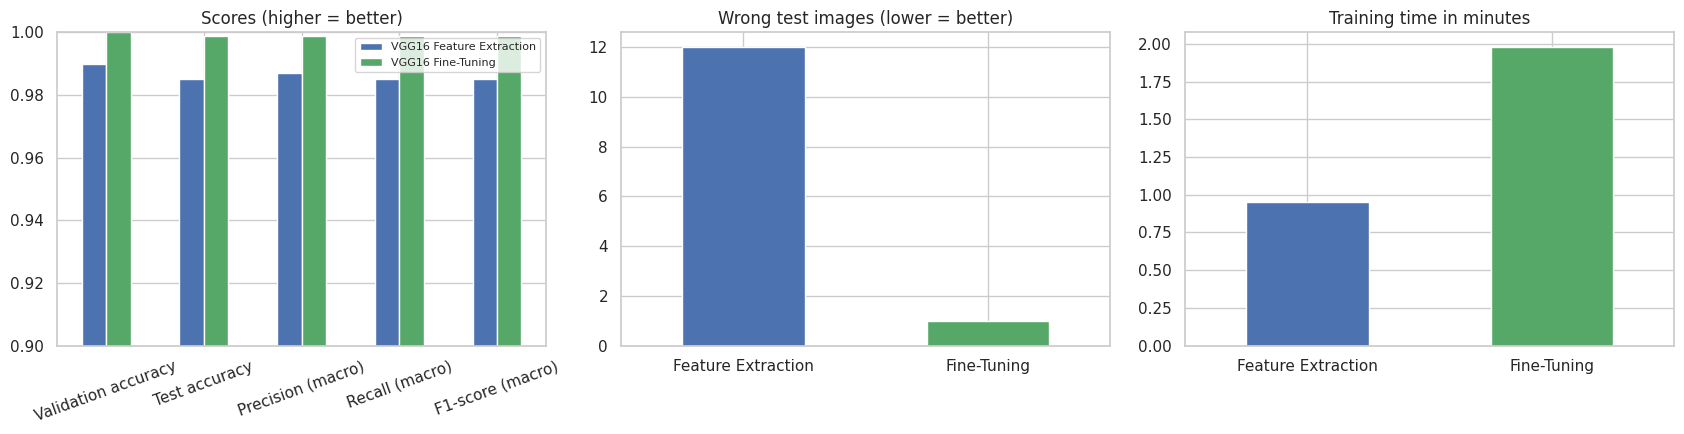

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
comparison.loc[["Validation accuracy", "Test accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]] \
    .plot(kind="bar", ax=axes[0], rot=20, color=["#4C72B0", "#55A868"])
axes[0].set_ylim(0.9, 1.0); axes[0].set_title("Scores (higher = better)"); axes[0].legend(fontsize=8)
comparison.loc["Wrong test images"].plot(kind="bar", ax=axes[1], rot=0, color=["#4C72B0", "#55A868"])
axes[1].set_title("Wrong test images (lower = better)")
comparison.loc["Training time (minutes)"].plot(kind="bar", ax=axes[2], rot=0, color=["#4C72B0", "#55A868"])
axes[2].set_title("Training time in minutes")
for ax in axes:
    ax.set_xticklabels([t.get_text().replace("VGG16 ", "") for t in ax.get_xticklabels()])
plt.tight_layout(); plt.savefig("results/model_comparison.png", dpi=120); plt.show()

In [39]:
# Is the difference real or just luck? (McNemar test: looks only at images where the models disagree)
only_fe_right = int(((preds_fe == y_test) & (preds_ft != y_test)).sum())
only_ft_right = int(((preds_ft == y_test) & (preds_fe != y_test)).sum())
p_value = binomtest(min(only_fe_right, only_ft_right), only_fe_right + only_ft_right).pvalue \
          if only_fe_right + only_ft_right > 0 else 1.0

banner("🔍 IS THE DIFFERENCE REAL?")
print(f"Images only Model 1 got right : {only_fe_right}")
print(f"Images only Model 2 got right : {only_ft_right}")
print(f"p-value                        : {p_value:.4f}")
print("➡️ The difference is REAL (p < 0.05)" if p_value < 0.05 else "➡️ The difference could be LUCK (p ≥ 0.05)")

══════════════════════════════════════════════════════════════════════
  🔍 IS THE DIFFERENCE REAL?
══════════════════════════════════════════════════════════════════════
Images only Model 1 got right : 1
Images only Model 2 got right : 12
p-value                        : 0.0034
➡️ The difference is REAL (p < 0.05)


**📖 How to interpret:**
- **Better model:** look at test accuracy, F1 and the number of wrong images.
- **Is it real?** If p < 0.05, the difference is very unlikely to be luck.
- **Cost:** fine-tuning trains about 53× more parameters, takes longer and gives a bigger file.
- **Which to use?** If accuracy matters most, use the more accurate one. If the two are almost equal, the simpler and faster one is enough.

## 📝 Results of this run (written from the outputs above)
*If you rerun on a Colab GPU, the numbers can change a little. Update this text from your own outputs.*

| | Model 1: Feature Extraction | Model 2: Fine-Tuning |
|---|---|---|
| Validation accuracy | 98.38% | **100%** |
| Test accuracy | 98.00% | **100%** |
| Macro F1 | 0.980 | **1.000** |
| Wrong test images (of 800) | 16 | **0** |
| Training time (CPU) | 21.4 min | 48.7 min (incl. Model 1) |
| Trainable parameters | 136,468 | 7,215,892 |

- **Transfer learning works:** with VGG16 frozen and only the small head trained, Model 1 already gets **98%** of the test images right.
- **Fine-tuning helps:** unfreezing `block5` fixed **all 16** mistakes of Model 1 and created **no** new ones (McNemar p < 0.0001), so the difference is real, not luck.
- **Model 1's mistakes** were mostly hands with spread fingers, such as **4 → 6**, **7 → 6** and **4 → 8**, plus **1 → 18** (one raised finger). These gestures look alike at 50×50 pixels.
- **The cost of fine-tuning:** about 2.3× the training time, 53× more trainable parameters and a file about twice as big (117 MB vs 61 MB).
- **Limitation:** each gesture comes from one video. The test images are later frames of the same video, so new people or cameras could be harder.

---
## 🟦 Step 14: Save the best model and predict one image
The augmentation and VGG16 preprocessing are **inside the model**, so predicting is easy. Just load the image with the **same `load_images` function** used for training and give it to the model.

✅ Saved models/best_model.keras (117 MB)
Image: 1182.jpg | true class: 1


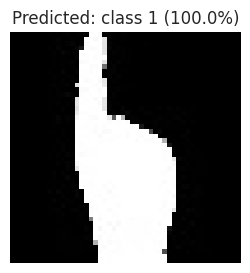

,class,probability
0,1,100.00%
1,18,0.00%
2,13,0.00%


In [40]:
best_model.save("models/best_model.keras")
with open("models/class_names.json", "w") as f:
    json.dump({"class_names": list(range(20)), "image_size": IMG_SIZE, "model": best_name}, f)
print("✅ Saved models/best_model.keras", f"({os.path.getsize('models/best_model.keras') / 1e6:.0f} MB)")

# Load it back (like in a new session) and predict one test image
loaded_model = keras.models.load_model("models/best_model.keras")

def predict_image(path):
    image = load_images([path])                         # same steps as training: RGB + 96x96
    probabilities = loaded_model.predict(image, verbose=0)[0]
    top3 = probabilities.argsort()[::-1][:3]
    plt.figure(figsize=(3, 3)); plt.imshow(Image.open(path), cmap="gray"); plt.axis("off")
    plt.title(f"Predicted: class {top3[0]} ({probabilities[top3[0]]:.1%})"); plt.show()
    return pd.DataFrame({"class": top3, "probability": probabilities[top3]}).style.format({"probability": "{:.2%}"})

example = test_df.sample(1, random_state=7).iloc[0]
print("Image:", example["filename"], "| true class:", example["label"])
predict_image(example["filepath"])

**To try your own image in Colab:**
```python
from google.colab import files
uploaded = files.upload()
predict_image(list(uploaded.keys())[0])
```
⚠️ The image must look like the training data: a **white hand on a black background**.

---
## 🟦 Step 15: Download the results

In [41]:
df.drop(columns=["md5"]).to_csv("results/dataset_table_df.csv", index=False)   # the df table itself
pred_df.to_csv("results/test_predictions.csv", index=False)
shutil.make_archive("my_results", "zip", "results")
banner("✅ All results saved in my_results.zip")
print(sorted(os.listdir("results")))

try:
    from google.colab import files
    files.download("my_results.zip")                    # downloads to your computer
except ImportError:
    pass

══════════════════════════════════════════════════════════════════════
  ✅ All results saved in my_results.zip
══════════════════════════════════════════════════════════════════════
['class_distribution.png', 'confusion_matrices.png', 'confusion_pairs.png', 'dataset_table_df.csv', 'history_feature_extraction.png', 'history_fine_tuning.png', 'model_comparison.csv', 'model_comparison.png', 'pixel_histogram.png', 'sample_images.png', 'test_predictions.csv', 'wrong_feature_extraction.png', 'wrong_fine_tuning.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

The model files are big (60–120 MB). To keep them, copy them to Google Drive:
```python
from google.colab import drive
drive.mount("/content/drive")
!cp models/best_model.keras /content/drive/MyDrive/
```

---
## 🛠️ Common problems

| Problem | Fix |
|---|---|
| `GPU: NO` / very slow | `Runtime → Change runtime type → T4 GPU` |
| `FileNotFoundError` / folder not found | upload `test.zip` again (uploads vanish when Colab disconnects) and run `!ls dataset` |
| `NameError: name 'df' is not defined` | a step was skipped: `Runtime → Run all` |
| `ResourceExhaustedError` / out of memory | change `batch_size=32` to `16`, then `Runtime → Restart session` |
| Accuracy stuck at about 5% | don't add your own `/255`; the model already preprocesses images |
| Weights download error | check the internet connection and run the cell again |
| Results slightly different each run | normal on a GPU |